**Wojciech Olejnik**

# Zadanie regresji

Celem laboratorium jest przebadanie dwóch kryteriów uczenia modelu liniowego : _MSE_ oraz _MAE_ oraz dwóch różnych form reguaryzacji modeli: _l<sup>1</sup>_ oraz _l<sup>2</sup>_.

# Przygotowanie danych

**Dane uczące i testowe dla modelu liniowego / nieliniowego modelu po n próbek:**

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import HuberRegressor
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings('ignore')


In [2]:
def data_for_linear_model(noise_flag=False, model='linear'):

    X = np.arange(-2, 2, 0.01)
    X = np.array(np.sort(np.random.rand(400)*4-2))
    
    
    noise = np.random.normal(0, 0.1, len(X))
    
    if noise_flag == True:
        noise = np.random.normal(0, 0.1, len(X))
        noise[[1, 10, 230, 310, 380]] = noise[[1, 10, 230, 310, 380]] + (np.random.rand() * 5)
        noise[50:100] = np.random.rand() * 10
    
    if model == 'linear':
        y = 0.7 * X + 0.2 + noise
    else:
        y = 0.7 * X**3 + 0.2 * X + 0.5 + noise
    
    return X, y

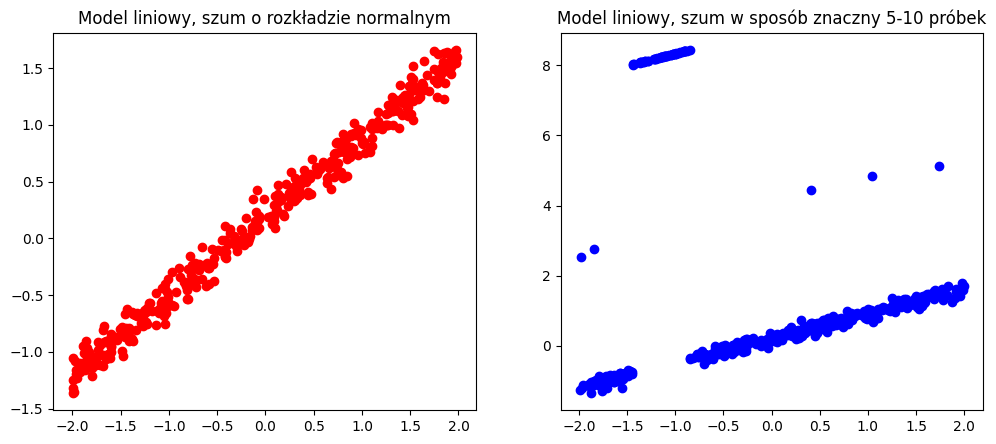

In [5]:
X1_train, y1_test = data_for_linear_model(False, 'linear')
X1_train_noise, y1_test_noise = data_for_linear_model(True, 'linear')

plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower

fig, axes = plt.subplots(1,2)
ax1 = axes[0]
ax2 = axes[1]
ax1.title.set_text('Model liniowy, szum o rozkładzie normalnym')
ax2.title.set_text('Model liniowy, szum w sposób znaczny 5-10 próbek')
ax1.scatter(X1_train, y1_test, c='red')
ax2.scatter(X1_train_noise, y1_test_noise, c='blue')

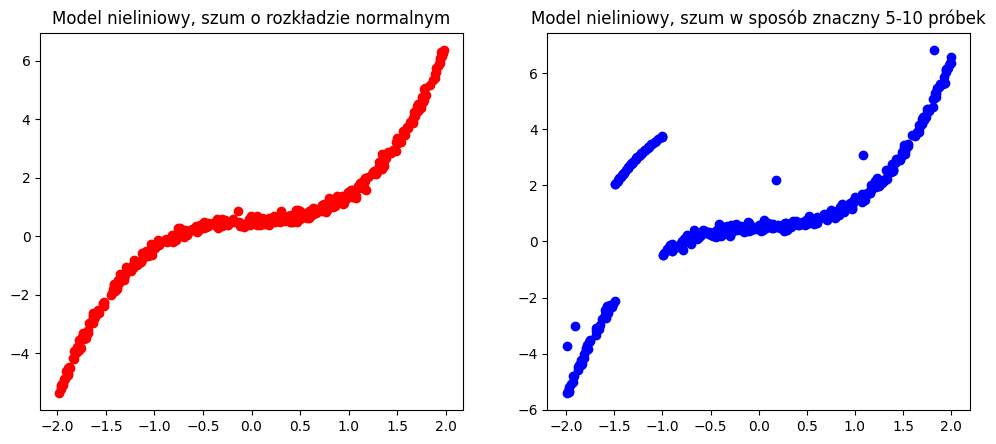

In [6]:
X2_train, y2_test = data_for_linear_model(False, 'non_linear')
X2_train_noise, y2_test_noise = data_for_linear_model(True, 'non_linear')

plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower

fig, axes = plt.subplots(1,2)
ax1 = axes[0]
ax2 = axes[1]
ax1.title.set_text('Model nieliniowy, szum o rozkładzie normalnym')
ax2.title.set_text('Model nieliniowy, szum w sposób znaczny 5-10 próbek')
ax1.scatter(X2_train, y2_test, c='red')
ax2.scatter(X2_train_noise, y2_test_noise, c='blue')

**Dla danych liniowych, dla dwóch wariantów szumu nastroić modele:**
- _LinearRegression_
- _Huber_
- _Ridge_
- _ElasticNet_
- _SGDRegressor_

Name LinearRegression(), score 0.8645850344518397, train_score 0.9855418935882131
Name HuberRegressor(), score 0.8665488912106075, train_score 0.9855204208782757
Name Ridge(), score 0.8631904294884403, train_score 0.9855325522262788
Name ElasticNet(), score 0.29444544985037713, train_score 0.4784139915662633
Name SGDRegressor(), score 0.8635958814516548, train_score 0.985524820712819


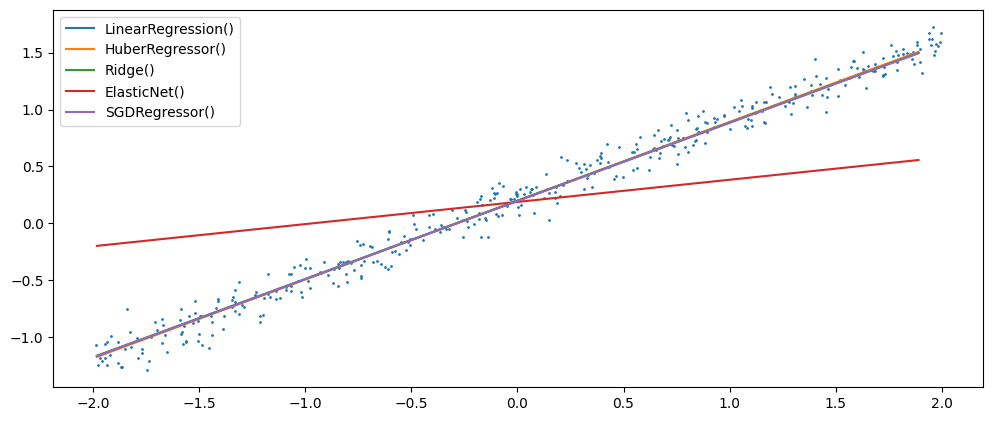

In [29]:
X_train, y_test = data_for_linear_model(False, 'linear')
# X1_train_noise, y1_test_noise = data_for_linear_model(True, 'linear')

models = [LinearRegression(), HuberRegressor(), Ridge(), ElasticNet(), SGDRegressor()]

X_train, X_test, y_train, y_test = train_test_split(X_train, y_test, test_size=0.33, random_state=42)
test_data = np.stack((X_test, y_test), axis=-1)
test_data = test_data[test_data[:, 0].argsort()]
X_test = test_data[:, 0]
y_test = test_data[:, 0]

fig, ax = plt.subplots()
ax.scatter(X.reshape(-1, 1), y, s=1)
for model in models:
    model.fit(X_train.reshape(-1, 1), y_train)
    y_pred = model.predict(X_test.reshape(-1, 1))
    score = model.score(X_test.reshape(-1, 1), y_test)
    train_score = model.score(X_train.reshape(-1, 1), y_train)
    print(f'Name {model}, score {score}, train_score {train_score}')
    ax.plot(X_test.reshape(-1, 1), y_pred, label=model)
    
plt.legend()
plt.show()

**Podsumowanie wyników dla modelu liniiowego z szumem o rozkładzie normalnym :**

| Model            | train_score         | score               |
|------------------|---------------------|---------------------|
| LinearRegression | 0.9825815950925447  | 0.8754428566823723  |
| HuberRegressor   | 0.9825274620843389  | 0.8733286976624433  |
| Ridge            | 0.9825728105203181  | 0.8741017991375066  |
| ElasticNet       | 0.49968656304237946 | 0.32505401393748623 |
| SGDRegressor     | 0.9825700998142606  | 0.874552974488291   |
 
**Podsumowanie:**
- LinearRegression, HuberRegression, Ridge oraz SGDRegressor poprawnie działają dla danych liniowych oraz dobrze poradziły sobie z szumem znormalizowanym. Wyniki badań dla tych modeli są prawie identyczne, dlatego proste wykresy dla nic założyły się
- ElasticNet dla danych liniowych nie pordził sobie za dobrze

Name LinearRegression(), score 0.8013187676545759, train_score 0.7894065872274113
Name HuberRegressor(), score 0.8405802282808196, train_score 0.7844123748956335
Name Ridge(), score 0.7998849757471309, train_score 0.7893999257293505
Name ElasticNet(), score 0.23291138818004276, train_score 0.3764607677796423
Name SGDRegressor(), score 0.7977052931459848, train_score 0.7893553447401025


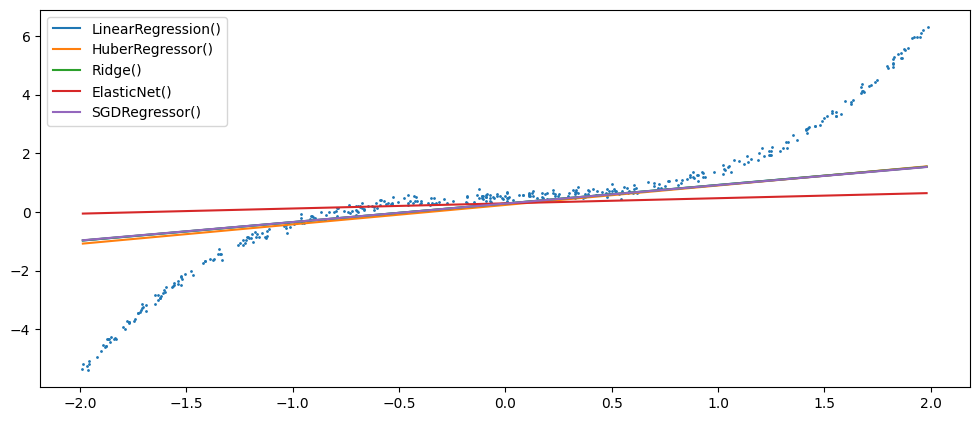

In [21]:
# X_train, y_test = data_for_linear_model(False, 'linear')
X_train, y_test = data_for_linear_model(True, 'linear')

plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower

models = [LinearRegression(), HuberRegressor(), Ridge(), ElasticNet(), SGDRegressor()]

X_train, X_test, y_train, y_test = train_test_split(X_train, y_test, test_size=0.33, random_state=42)
test_data = np.stack((X_test, y_test), axis=-1)
test_data = test_data[test_data[:, 0].argsort()]
X_test = test_data[:, 0]
y_test = test_data[:, 0]

fig, ax = plt.subplots()
ax.scatter(X.reshape(-1, 1), y, s=1)
for model in models:
    model.fit(X_train.reshape(-1, 1), y_train)
    y_pred = model.predict(X_test.reshape(-1, 1))
    score = model.score(X_test.reshape(-1, 1), y_test)
    train_score = model.score(X_train.reshape(-1, 1), y_train)
    print(f'Name {model}, score {score}, train_score {train_score}')
    ax.plot(X_test.reshape(-1, 1), y_pred, label=model)
    
plt.legend()

**Podsumowanie wyników dla modelu liniiowego z szumem w zbiorze uczącym zaburzonym w sposób znaczny 5-10 próbek :**

| Model            | train_score         | score               |
|------------------|---------------------|---------------------|
| LinearRegression | 0.5488435792038535  | 0.6677142996872034  |
| HuberRegressor   | 0.4676115097484739  | 0.8539170865430901  |
| Ridge            | 0.548839082211187   | 0.6661784285350084  |
| ElasticNet       | 0.18354252852599973 | 0.0509204527559326  |
| SGDRegressor     | 0.5488265516432133  | 0.6698630599103512  |
 
**Podsumowanie:**
- LinearRegression, Ridge oraz SGDRegressor wzgledem poprzdniego użyciu szumu otrzymały wyniki 2 razy mniejsze niż poprzednio i wynikiem tego jest złe dopasowanie do danych
- ElasticNet względem poprzedniego badania otrzymał podobne wyniki
- HuberRegression jako jedyny poprawnie dopasowuje się do dane

**Dla danych nieliniowych, dla dwóch wariantów szumu nastroić modele:**
- _LinearRegression_
- _Huber_
- _Ridge_
- _ElasticNet_
- _SGDRegressor_

oraz za pomocą **_PolynomialFeatures(deg)_** dodamy warstwe pośrednią.
Dodamy do porównania równie model sieci neuronowej z liniową funkcją aktywacji na wyjsciu:
**_MLPRegresqsor_**,oraz liczbę neuronów w warstwie ukrytej równą **_deg_ .**

Name LinearRegression(), score 0.3017606204928349, train_score 0.8590562941616349, deg 2
Name HuberRegressor(), score 0.5328754300345585, train_score 0.8508718566473951, deg 2
Name Ridge(), score 0.3099248499654792, train_score 0.8590487277260477, deg 2
Name ElasticNet(), score 0.8887263406407686, train_score 0.6863420660781425, deg 2
Name SGDRegressor(), score 0.30435912898334205, train_score 0.859040280414771, deg 2


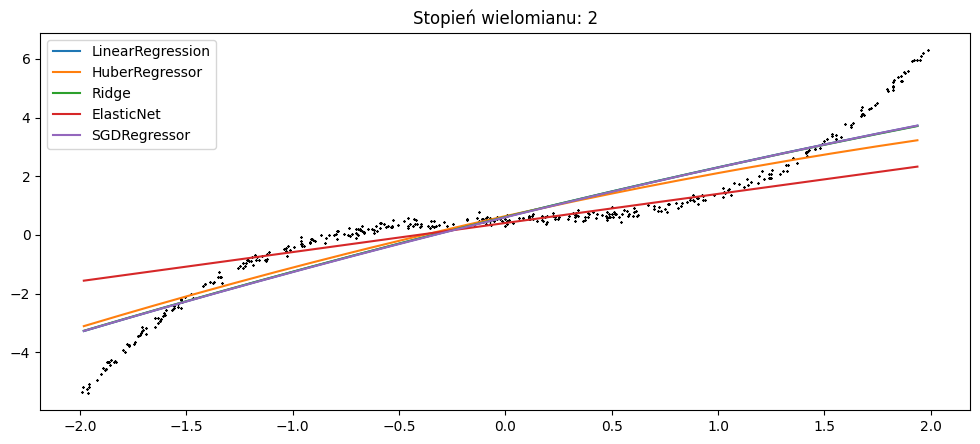

Name LinearRegression(), score -0.5080336243465926, train_score 0.9975461913403775, deg 5
Name HuberRegressor(), score -0.5059793591132762, train_score 0.9975373258325764, deg 5
Name Ridge(), score -0.5086650390357574, train_score 0.9975340732712751, deg 5
Name ElasticNet(), score -0.750455163910501, train_score 0.9350594562991041, deg 5
Name SGDRegressor(), score -0.5504183107299312, train_score 0.9965697802810709, deg 5


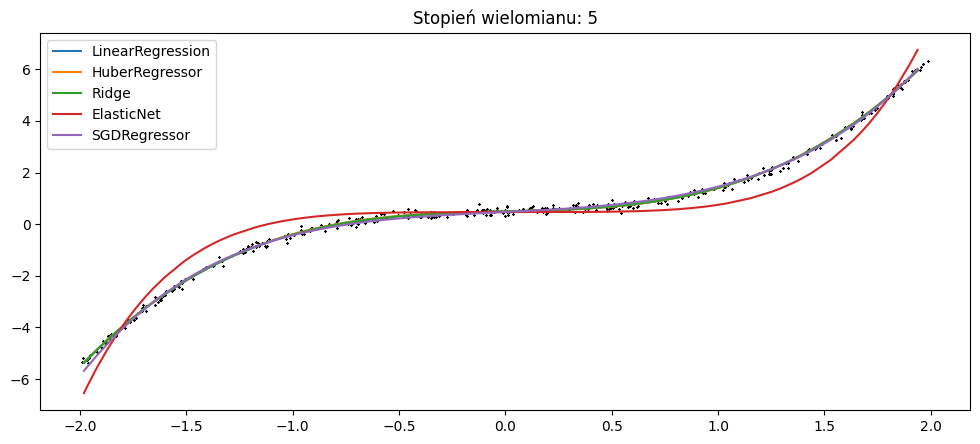

Name LinearRegression(), score -0.4948230681286727, train_score 0.997620155524377, deg 10
Name HuberRegressor(), score -0.49592309908236776, train_score 0.997239005248879, deg 10
Name Ridge(), score -0.4973971917139868, train_score 0.9976123512398275, deg 10
Name ElasticNet(), score -0.6906671534251909, train_score 0.9532350556464497, deg 10
Name SGDRegressor(), score -1.8114678352243807e+28, train_score -3.6446978325115394e+27, deg 10


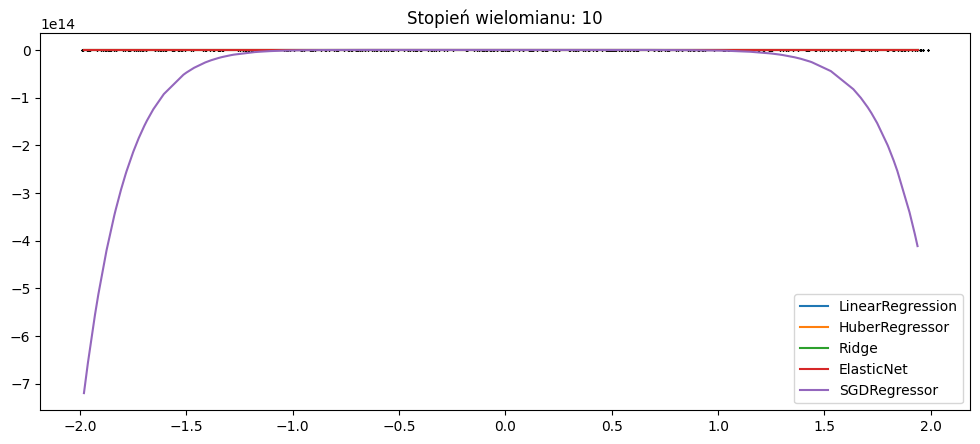

In [28]:
X_train, y_test = data_for_linear_model(False, 'non_linear')
# X_train, y_test = data_for_linear_model(True, 'non_linear')

models = [LinearRegression(), HuberRegressor(), Ridge(), ElasticNet(), SGDRegressor()]

X_train, X_test, y_train, y_test = train_test_split(X_train, y_test, test_size=0.33, random_state=42)
test_data = np.stack((X_test, y_test), axis=-1)
test_data = test_data[test_data[:, 0].argsort()]
X_test = test_data[:, 0]
y_test = test_data[:, 0]

plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower

for deg in [2, 5, 10]:
    fig, ax = plt.subplots()
    ax.scatter(X.reshape(-1, 1), y, marker='x', c='k', s=1,)
    for model in models:
        pipe = Pipeline([('poly', PolynomialFeatures(deg)), ('clf', model)])
        pipe.fit(X_train.reshape(-1, 1), y_train)
        y_pred = pipe.predict(X_test.reshape(-1, 1))
        score = pipe.score(X_test.reshape(-1, 1), y_test)
        train_score = pipe.score(X_train.reshape(-1, 1), y_train)
        print(f'Name {model}, score {score}, train_score {train_score}, deg {deg}')
        ax.plot(X_test.reshape(-1, 1), y_pred, label=model.__class__.__name__)
    
    plt.title(f"Stopień wielomianu: {deg}")
    plt.legend()
    plt.show()


Name LinearRegression(), score -0.5723522762077355, train_score 0.9979112516617612, deg 10
Name HuberRegressor(), score -0.5584463778172379, train_score 0.9975887561952612, deg 10
Name Ridge(), score -0.569842034890838, train_score 0.9978647659087218, deg 10
Name ElasticNet(), score -0.7870906707262679, train_score 0.9540792634643924, deg 10


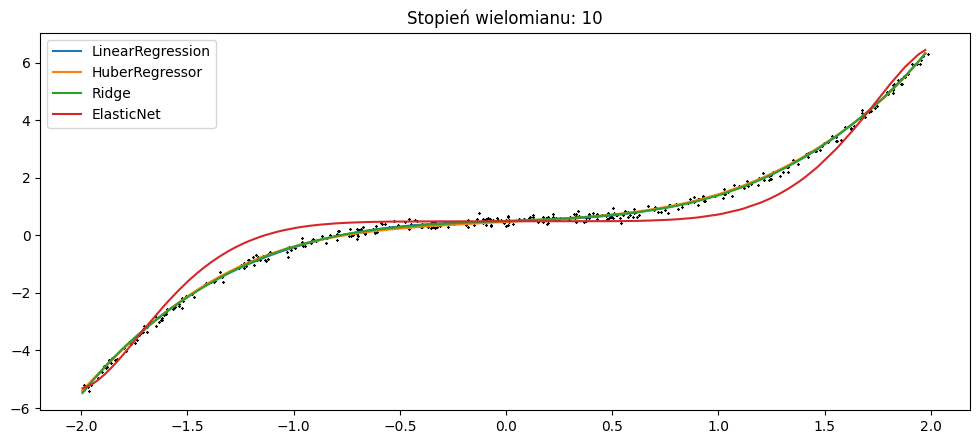

In [27]:
X_train, y_test = data_for_linear_model(False, 'non_linear')
# X_train, y_test = data_for_linear_model(True, 'non_linear')

models = [LinearRegression(), HuberRegressor(), Ridge(), ElasticNet()]

X_train, X_test, y_train, y_test = train_test_split(X_train, y_test, test_size=0.33, random_state=42)
test_data = np.stack((X_test, y_test), axis=-1)
test_data = test_data[test_data[:, 0].argsort()]
X_test = test_data[:, 0]
y_test = test_data[:, 0]

plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower

for deg in [10]:
    fig, ax = plt.subplots()
    ax.scatter(X.reshape(-1, 1), y, marker='x', c='k', s=1,)
    for model in models:
        pipe = Pipeline([('poly', PolynomialFeatures(deg)), ('clf', model)])
        pipe.fit(X_train.reshape(-1, 1), y_train)
        y_pred = pipe.predict(X_test.reshape(-1, 1))
        score = pipe.score(X_test.reshape(-1, 1), y_test)
        train_score = pipe.score(X_train.reshape(-1, 1), y_train)
        print(f'Name {model}, score {score}, train_score {train_score}, deg {deg}')
        ax.plot(X_test.reshape(-1, 1), y_pred, label=model.__class__.__name__)
    
    plt.title(f"Stopień wielomianu: {deg}")
    plt.legend()
    plt.show()

**Podsumowanie wyników dla modelu nieliniiowego z szumem o rozkładzie normalnym :**

|                        |Stopień wielomianu = 2  |                 |
|:----------------------:|:------------------:|:-------------------:|
| Model                  | train_score        | score               |
| LinearRegression       | 0.8535686304882197 | 0.32920576262335266 |
| HuberRegressor         | 0.8417557424999753 | 0.584681500234863   |
| Ridge                  | 0.8535595811890828 | 0.33718861954089707 |
| ElasticNet             | 0.6571866783568101 | 0.809502575688932   |
| SGDRegressor           | 0.8534553430622871 | 0.3162828446221657  |

|                         | Stopień wielomianu = 10|                        |
|:-----------------------:|:----------------------:|:----------------------:|
| Model                   | train_score            | score                  |
| LinearRegression        | 0.997326578982943      | -0.5089835802630867    |
| HuberRegressor          | 0.9971525847053926     | -0.5203431962056635    |
| Ridge                   | 0.9972952046037045     | -0.5072769663572927    |
| ElasticNet              | 0.949835521075319      | -0.7173603174139236    |
| SGDRegressor            | -7.094589431367125e+27 | -3.409597108369147e+28 |
 
**Podsumowanie:**
- LinearRegression, HuberRegression, Ridge, SGDRegressor oraz ElasticNet dla danych nieliniowych, z szumem znormalizowanym dla oraz warstwą cech wielomianowych równą 2 nie porawdziły sobie z dopasowaniem danych.
- LinearRegression, HuberRegression, Ridge, SGDRegressor dla danych nieliniowych, z szumem znormalizowanym dla oraz warstwą cech wielomianowych równą 5 porawdziły sobie z dopasowaniem danych. ElasticNet trochę odbiega od poprawnego dopasowania
- LinearRegression, HuberRegression, Ridge dla danych nieliniowych, z szumem znormalizowanym dla oraz warstwą cech wielomianowych równą 10 porawdziły sobie z dopasowaniem danych. ElasticNet trochę odbiega od poprawnego dopasowania. Za to SGDRegressor nie zupełnie nie poradził sobie z doposowaniem danych, dlatego postanowiono nie plotować go na wykresie.

Name LinearRegression(), score -1.1855407386565266, train_score 0.0798936498369951, deg 2
Name HuberRegressor(), score 0.10971604861876605, train_score 0.007797975642906407, deg 2
Name Ridge(), score -1.1858959237850435, train_score 0.07989295557478826, deg 2
Name ElasticNet(), score -1.492026485244724, train_score 0.03055843926805213, deg 2


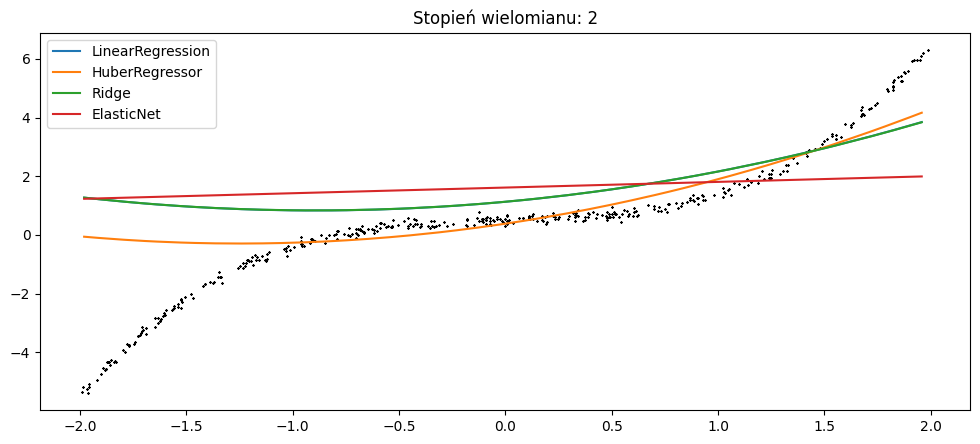

Name LinearRegression(), score -6.9407667161308, train_score 0.7154510291829985, deg 10
Name HuberRegressor(), score -0.8824779351657128, train_score 0.25160189191079085, deg 10
Name Ridge(), score -6.2725725185151155, train_score 0.6848660061618257, deg 10
Name ElasticNet(), score -2.443598206137239, train_score 0.32677193327226794, deg 10


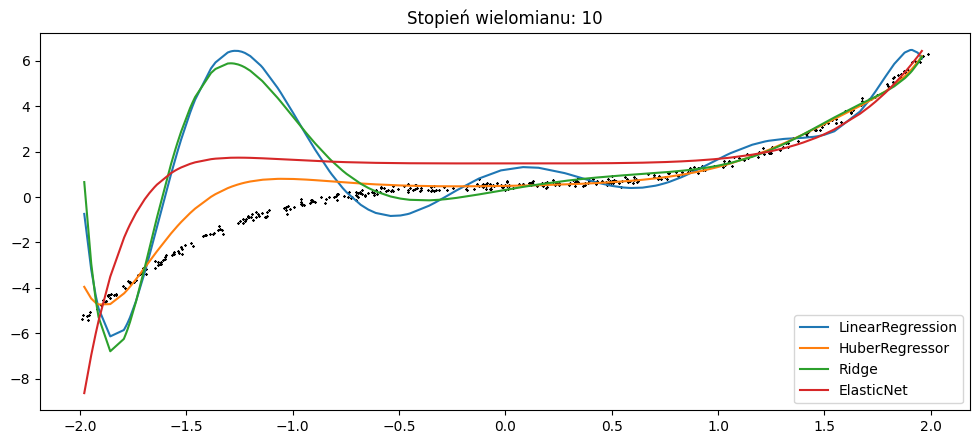

In [30]:
# X_train, y_test = data_for_linear_model(False, 'non_linear')
X_train, y_test = data_for_linear_model(True, 'non_linear')

models = [LinearRegression(), HuberRegressor(), Ridge(), ElasticNet()]

X_train, X_test, y_train, y_test = train_test_split(X_train, y_test, test_size=0.33, random_state=42)
test_data = np.stack((X_test, y_test), axis=-1)
test_data = test_data[test_data[:, 0].argsort()]
X_test = test_data[:, 0]
y_test = test_data[:, 0]

plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100 # 200 e.g. is really fine, but slower

for deg in [2, 10]:
    fig, ax = plt.subplots()
    ax.scatter(X.reshape(-1, 1), y, marker='x', c='k', s=1,)
    for model in models:
        pipe = Pipeline([('poly', PolynomialFeatures(deg)), ('clf', model)])
        pipe.fit(X_train.reshape(-1, 1), y_train)
        y_pred = pipe.predict(X_test.reshape(-1, 1))
        score = pipe.score(X_test.reshape(-1, 1), y_test)
        train_score = pipe.score(X_train.reshape(-1, 1), y_train)
        print(f'Name {model}, score {score}, train_score {train_score}, deg {deg}')
        ax.plot(X_test.reshape(-1, 1), y_pred, label=model.__class__.__name__)
    
    plt.title(f"Stopień wielomianu: {deg}")
    plt.legend()
    plt.show()

**Podsumowanie wyników dla modelu nieliniiowego z szumem na zbiorze uczącym zaburzającym 5-10 próbek :**

|                        |Stopień wielomianu = 2 |                     |
|:----------------------:|:---------------------:|:-------------------:|
| Model                  | train_score           | score               |
| LinearRegression       | 0.0798936498369951    | -1.1855407386565266 |
| HuberRegressor         | 0.007797975642906407  | 0.10971604861876605 |
| Ridge                  | 0.07989295557478826   | -1.1858959237850435 |
| ElasticNet             | 0.03055843926805213   | -1.492026485244724  |


|                         | Stopień wielomianu = 10|                        |
|:-----------------------:|:----------------------:|:----------------------:|
| Model                   | train_score            | score                  |
| LinearRegression        | 0.7154510291829985     | -6.9407667161308       |
| HuberRegressor          | 0.25160189191079085    | -0.8824779351657128    |
| Ridge                   | 0.6848660061618257     | -6.2725725185151155    |
| ElasticNet              | 0.32677193327226794    | -2.443598206137239     |

 
**Podsumowanie:**
- SGDRegressor został porzucony w plotowaniu ponieważ duże zmienny wartości na wykresie
- LinearRegression, HuberRegression, Ridge, SGDRegressor oraz ElasticNet dla danych nieliniowych, z szumem na wybranych próbkach oraz warstwą cech wielomianowych zarówno dla stopnia 2 oraz 10 nie dopasował się do danych.
- Najblizej dopasowania był HuberRegression(), gdzie dla większości zbioru dobrze się dopasował
- LinearRegression i Ridge próbują dopasować dane odstające.